# Dehydrated xylem vessels: human annotation vs Cellpose-SAM

For reviewer comment 2 (independent check of the instance reference). For each selected slice:

1. **Human annotation**: dehydrated xylem vessels (class 7) from the manually drawn semantic mask
   (`data/annotations/{slice}_mask.npy`) → regions and their polygons.
2. **Cellpose-SAM**: instance masks (`data/instance_masks/{slice}_masks.tif`) → the Cellpose-SAM cells that lie in the
   dehydrated regions (selected with a slightly **relaxed**, dilated region so that cells extending a little beyond the
   hand-drawn outline are not cut off). The selected cells are then **merged into regions** (small gaps between
   neighbouring cells closed, holes filled), because the human annotation outlines regions, not individual cells.
3. **Comparison of the two region masks / polygons**: area difference, IoU, Dice, precision, recall and boundary distance
   (mean, 95th percentile). Cell counts are not compared.

Note: in the pipeline (`2get_class_mask.ipynb`) a Cellpose-SAM cell gets class 7 because it overlaps the human region,
so *which* cells are dehydrated xylem is not independent of the human mask. What this notebook measures independently is
the **delineation**: how well the Cellpose-SAM cell outlines reproduce the human-drawn vessel outlines.

In [1]:
# =============================================================================
# Config
# =============================================================================
from pathlib import Path

DATA_DIR = Path("./data")          # on NERSC: /pscratch/sd/x/xchong/sam3_finetune/seg_annotation_pipeline2_7classes/data
SLICES = [
    "20260212_133951_petiole30_00100",
    "20260212_174538_petiole36_00100",
    "20260213_145242_petiole47_00100",
]
DEHYD = 7                          # class id of dehydrated xylem vessels in the semantic mask

RELAX_PX = 5                       # dilation of the human region before selecting Cellpose cells (relaxed boundary)
MIN_CELL_FRACTION = 0.5            # a Cellpose cell is kept if >= this fraction of its area lies in the relaxed region
MIN_REGION_AREA = 20               # px; ignore tiny fragments (both masks)
MERGE_PX = 3                       # close gaps between neighbouring Cellpose cells (cell walls) up to ~2*MERGE_PX px

OUT_DIR = Path("./dehydrated_xylem_human_vs_cellpose")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from scipy import ndimage as ndi

def find(d, stem, suffixes):
    for s in suffixes:
        p = Path(d) / f"{stem}{s}"
        if p.exists():
            return p
    raise FileNotFoundError(f"{stem}{suffixes} not in {d}")

def load_image(stem):
    a = np.array(Image.open(find(DATA_DIR / "images", stem, (".tiff", ".tif")))).astype(np.float32)
    lo, hi = np.percentile(a, (0.5, 99.5))
    return np.clip((a - lo) / max(hi - lo, 1e-6), 0, 1)

def load_semantic(stem):
    return np.load(find(DATA_DIR / "annotations", stem, ("_mask.npy",)))

def load_instances(stem):
    a = np.array(Image.open(find(DATA_DIR / "instance_masks", stem, ("_masks.tif", "_masks.tiff"))))
    return (a[..., 0] if a.ndim == 3 else a).astype(np.int64)

def disk(r):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

def mask_to_polygons(mask):
    """Outer polygons of a binary mask (one per connected region), as lists of (x, y)."""
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c[:, 0, :].tolist() for c in contours if len(c) >= 3]

def labels_to_polygons(lab):
    """One polygon per instance id."""
    polys = {}
    for obj_id, sl in enumerate(ndi.find_objects(lab), start=1):
        if sl is None:
            continue
        sub = (lab[sl] == obj_id).astype(np.uint8)
        cs, _ = cv2.findContours(sub, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if cs:
            c = max(cs, key=cv2.contourArea)[:, 0, :] + np.array([sl[1].start, sl[0].start])
            polys[obj_id] = c.tolist()
    return polys

def rasterize(polys, shape):
    m = np.zeros(shape, np.uint8)
    for p in polys:
        cv2.fillPoly(m, [np.asarray(p, np.int32)], 1)
    return m.astype(bool)

def boundary(mask):
    return mask & ~ndi.binary_erosion(mask, structure=np.ones((3, 3)))

def boundary_distances(a, b):
    """Distances from boundary pixels of a to the boundary of b and vice versa (px)."""
    ba, bb = boundary(a), boundary(b)
    if not ba.any() or not bb.any():
        return np.array([np.nan])
    da = ndi.distance_transform_edt(~bb)[ba]
    db = ndi.distance_transform_edt(~ba)[bb]
    return np.concatenate([da, db])

## Human regions, Cellpose-SAM cells, polygons and comparison

In [3]:
rows, cache = [], {}
for stem in SLICES:
    sem, inst = load_semantic(stem), load_instances(stem)
    assert sem.shape == inst.shape, f"{stem}: {sem.shape} vs {inst.shape}"

    # ---- 1. human: dehydrated xylem regions ----
    human = sem == DEHYD
    lab_h, _ = ndi.label(human, structure=np.ones((3, 3)))
    sizes = np.bincount(lab_h.ravel()); keep = sizes >= MIN_REGION_AREA; keep[0] = False
    human = keep[lab_h]

    # ---- 2. Cellpose-SAM cells inside the relaxed human region, merged into regions ----
    relaxed = cv2.dilate(human.astype(np.uint8), disk(RELAX_PX)).astype(bool) if RELAX_PX > 0 else human
    area = np.bincount(inst.ravel())
    inside = np.bincount(inst.ravel(), weights=relaxed.ravel(), minlength=len(area))
    frac = inside / np.maximum(area, 1)
    sel_ids = np.nonzero((frac >= MIN_CELL_FRACTION) & (np.arange(len(area)) > 0))[0]
    cells = np.isin(inst, sel_ids)
    cp_region = cells
    if MERGE_PX > 0:   # cells -> region: close the walls between neighbouring cells, fill holes
        cp_region = cv2.morphologyEx(cells.astype(np.uint8), cv2.MORPH_CLOSE, disk(MERGE_PX)).astype(bool)
    cp_region = ndi.binary_fill_holes(cp_region)
    lab_c, _ = ndi.label(cp_region, structure=np.ones((3, 3)))
    sz = np.bincount(lab_c.ravel()); kc = sz >= MIN_REGION_AREA; kc[0] = False
    cp_region = kc[lab_c]
    human = ndi.binary_fill_holes(human)
    human_polys, cp_polys = mask_to_polygons(human), mask_to_polygons(cp_region)

    # ---- 3. compare the two regions (polygons rasterised back to masks) ----
    H = rasterize(human_polys, human.shape)
    C = rasterize(cp_polys, human.shape)
    inter, union = (H & C).sum(), (H | C).sum()
    bd = boundary_distances(H, C)
    rows.append(dict(slice=stem, human_area_px=int(H.sum()), cellpose_area_px=int(C.sum()),
                     area_diff_pct=100 * (C.sum() - H.sum()) / max(H.sum(), 1),
                     IoU=inter / max(union, 1), Dice=2 * inter / max(H.sum() + C.sum(), 1),
                     precision=inter / max(C.sum(), 1), recall=inter / max(H.sum(), 1),
                     boundary_mean_px=np.nanmean(bd), boundary_p95_px=np.nanpercentile(bd, 95)))
    cache[stem] = dict(H=H, C=C, human_polys=human_polys, cp_polys=cp_polys)

    # polygons for reuse
    json.dump({"slice": stem, "class": "Dehydrated Xylem vessels",
               "human_region_polygons": human_polys, "cellpose_region_polygons": cp_polys,
               "settings": dict(RELAX_PX=RELAX_PX, MIN_CELL_FRACTION=MIN_CELL_FRACTION, MERGE_PX=MERGE_PX)},
              open(OUT_DIR / f"{stem}_polygons.json", "w"))
    print(f"{stem}: region IoU {rows[-1]['IoU']:.3f}, Dice {rows[-1]['Dice']:.3f}")

per_slice = pd.DataFrame(rows).set_index("slice")

20260212_133951_petiole30_00100: region IoU 0.855, Dice 0.922
20260212_174538_petiole36_00100: region IoU 0.667, Dice 0.800
20260213_145242_petiole47_00100: region IoU 0.604, Dice 0.753


## Results

In [4]:
# totals over the 3 slices (pixel metrics pooled; boundary distances averaged over slices)
Hs = sum(c["H"].sum() for c in cache.values()); Cs = sum(c["C"].sum() for c in cache.values())
I = sum((c["H"] & c["C"]).sum() for c in cache.values()); U = sum((c["H"] | c["C"]).sum() for c in cache.values())
total = dict(human_area_px=int(Hs), cellpose_area_px=int(Cs), area_diff_pct=100 * (Cs - Hs) / max(Hs, 1),
             IoU=I / max(U, 1), Dice=2 * I / max(Hs + Cs, 1), precision=I / max(Cs, 1), recall=I / max(Hs, 1),
             boundary_mean_px=per_slice["boundary_mean_px"].mean(), boundary_p95_px=per_slice["boundary_p95_px"].mean())
table = pd.concat([per_slice, pd.DataFrame([total], index=["all 3 slices"])])
pd.options.display.float_format = "{:.3f}".format
display(table)
table.to_csv(OUT_DIR / "comparison_per_slice.csv")

,human_area_px,cellpose_area_px,area_diff_pct,IoU,Dice,precision,recall,boundary_mean_px,boundary_p95_px
20260212_133951_petiole30_00100,120018,118191,-1.522,0.855,0.922,0.929,0.915,1.653,4.123
20260212_174538_petiole36_00100,112458,79040,-29.716,0.667,0.800,0.969,0.681,7.731,10.770
20260213_145242_petiole47_00100,216631,134447,-37.937,0.604,0.753,0.983,0.610,11.507,17.464
all 3 slices,449107,331678,-26.147,0.689,0.816,0.960,0.709,6.963,10.786


## Plots

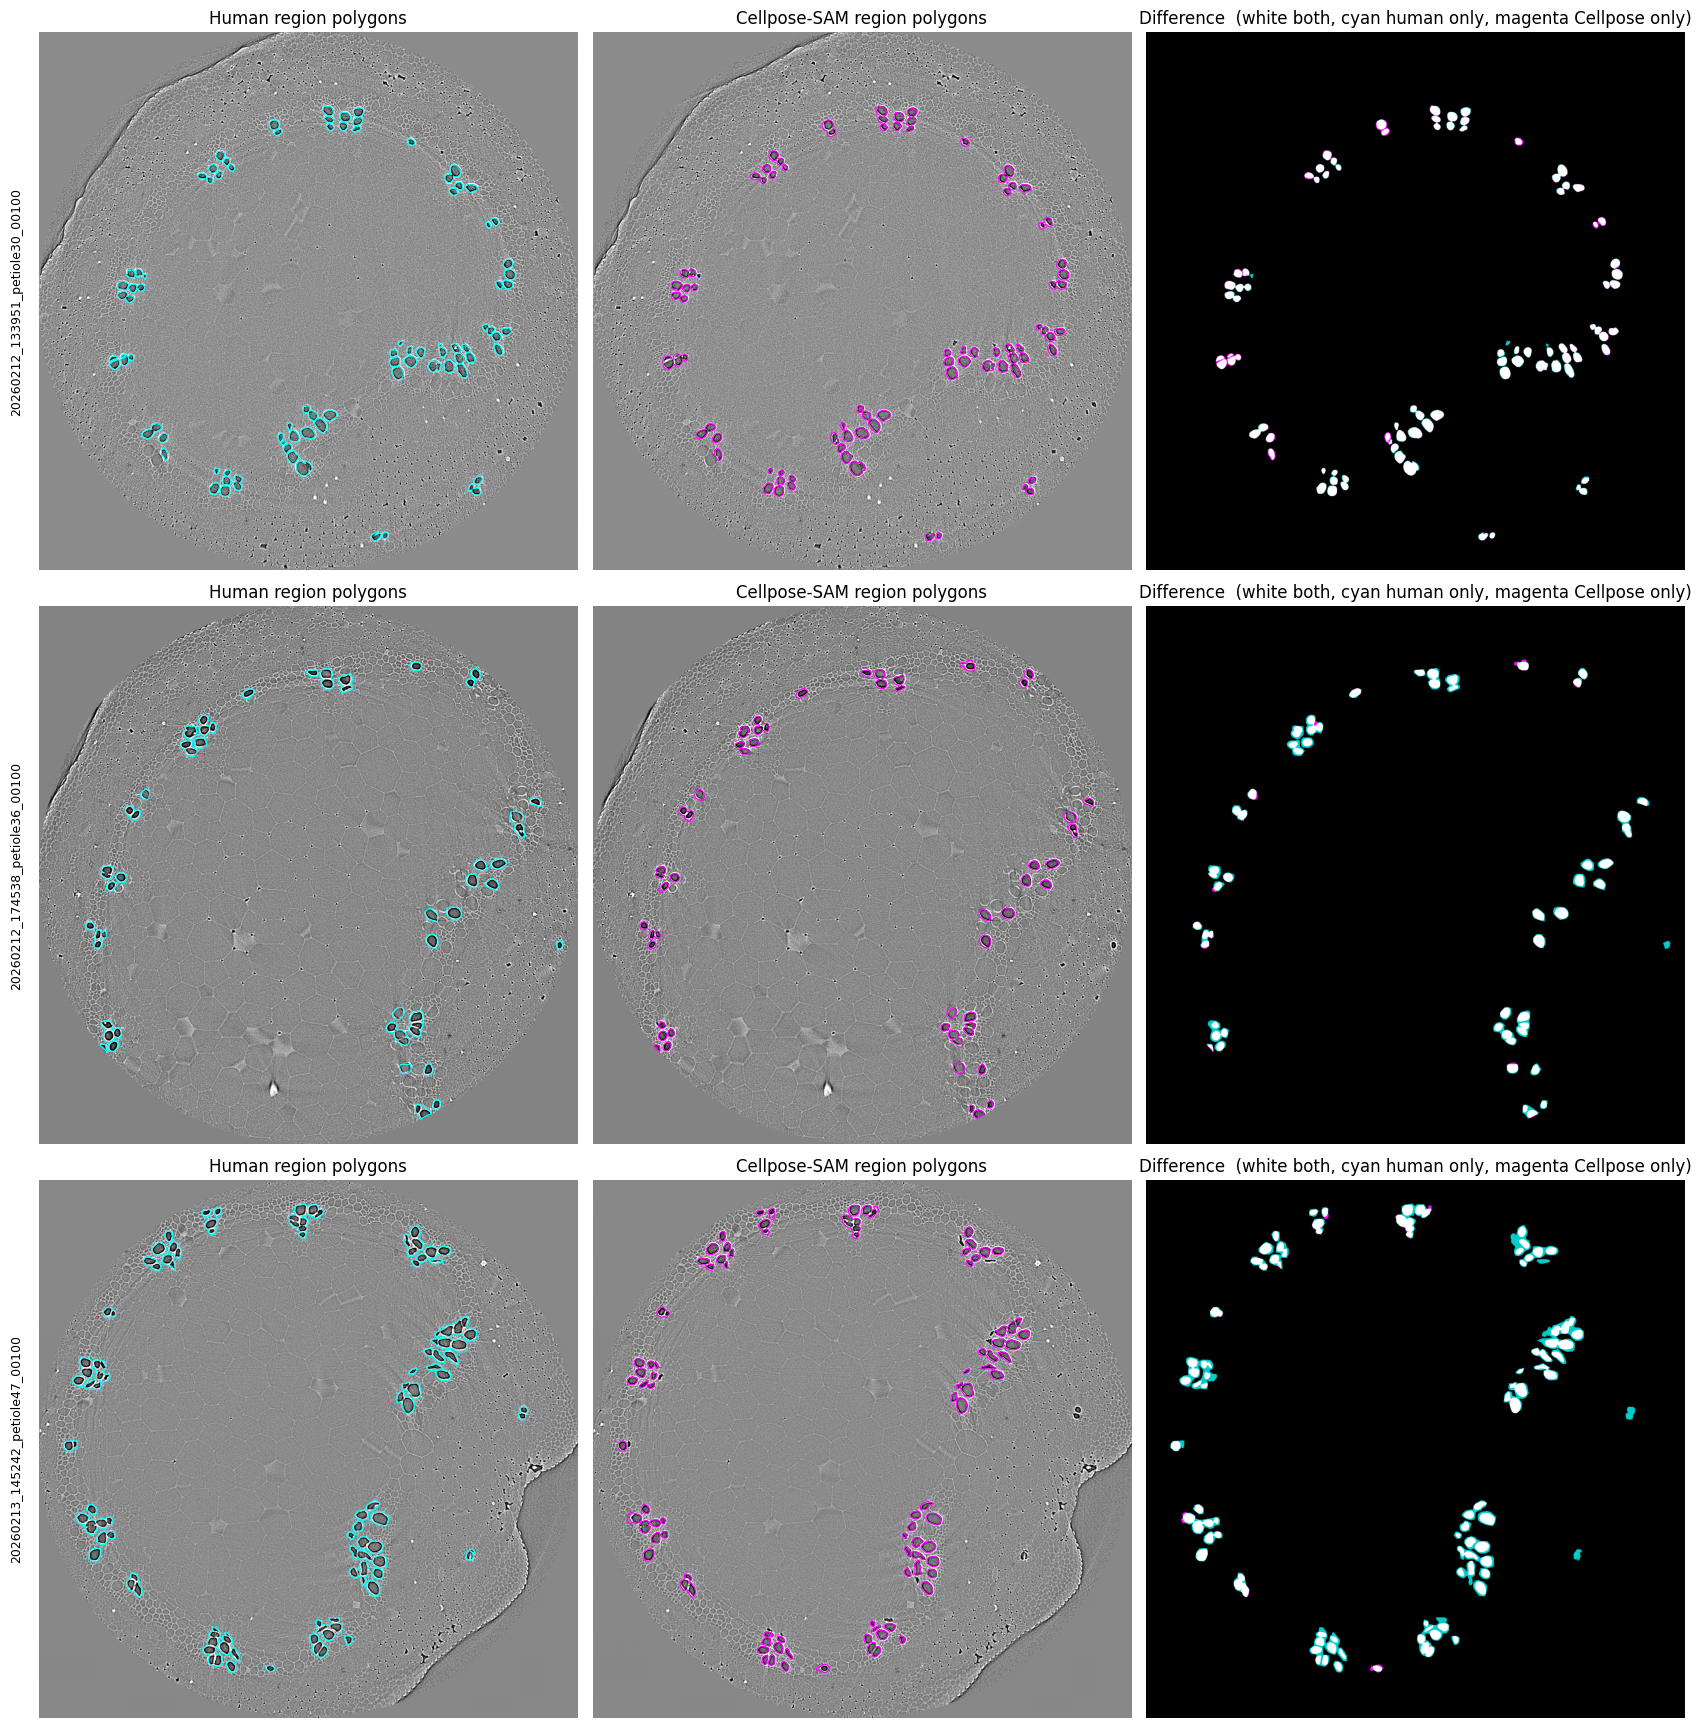

20260212_133951_petiole30_00100:  IoU 0.855  Dice 0.922  precision 0.929  recall 0.915  area diff -1.5%  boundary mean 1.7 px  p95 4.1 px
20260212_174538_petiole36_00100:  IoU 0.667  Dice 0.800  precision 0.969  recall 0.681  area diff -29.7%  boundary mean 7.7 px  p95 10.8 px
20260213_145242_petiole47_00100:  IoU 0.604  Dice 0.753  precision 0.983  recall 0.610  area diff -37.9%  boundary mean 11.5 px  p95 17.5 px
all 3 slices                   :  IoU 0.689  Dice 0.816  precision 0.960  recall 0.709  area diff -26.1%  boundary mean 7.0 px  p95 10.8 px


In [5]:
def draw(ax, img, polys, color, title):
    ax.imshow(img, cmap="gray")
    for p in polys:
        p = np.asarray(p)
        ax.plot(np.r_[p[:, 0], p[0, 0]], np.r_[p[:, 1], p[0, 1]], color=color, lw=0.8)
    ax.set_title(title); ax.axis("off")

fig, axes = plt.subplots(len(SLICES), 3, figsize=(17, 5.8 * len(SLICES)), squeeze=False)
for row, stem in enumerate(SLICES):
    c = cache[stem]; img = load_image(stem)          # full slice (all slices have the same size)
    draw(axes[row, 0], img, c["human_polys"], "cyan", "Human region polygons")
    draw(axes[row, 1], img, c["cp_polys"], "magenta", "Cellpose-SAM region polygons")
    diff = np.zeros(img.shape + (3,))
    Hc, Cc = c["H"], c["C"]
    diff[Hc & Cc] = (1, 1, 1); diff[Hc & ~Cc] = (0, 0.8, 0.8); diff[~Hc & Cc] = (1, 0, 1)
    axes[row, 2].imshow(diff); axes[row, 2].axis("off")
    axes[row, 2].set_title("Difference  (white both, cyan human only, magenta Cellpose only)")
    axes[row, 0].text(-0.03, 0.5, stem, transform=axes[row, 0].transAxes, rotation=90, ha="right", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "human_vs_cellpose_all_slices.png", dpi=150); plt.show()

# metrics, printed after the figure
for stem in SLICES:
    r = per_slice.loc[stem]
    print(f"{stem}:  IoU {r.IoU:.3f}  Dice {r.Dice:.3f}  precision {r.precision:.3f}  recall {r.recall:.3f}  "
          f"area diff {r.area_diff_pct:+.1f}%  boundary mean {r.boundary_mean_px:.1f} px  p95 {r.boundary_p95_px:.1f} px")
r = table.loc["all 3 slices"]
print(f"{'all 3 slices':31s}:  IoU {r.IoU:.3f}  Dice {r.Dice:.3f}  precision {r.precision:.3f}  recall {r.recall:.3f}  "
      f"area diff {r.area_diff_pct:+.1f}%  boundary mean {r.boundary_mean_px:.1f} px  p95 {r.boundary_p95_px:.1f} px")